# Multi-head latent attention, from projections to a compressed cache

This notebook builds the MLA attention computation used in our MLX GPT.
It assumes familiarity with linear layers, softmax attention and backpropagation.
Run cells in order using the project's MLX environment with the analysis extra.

MLA gives every token a shared KV latent vector. Learned projections map that
vector into each head's content keys and values. A separate small branch carries
RoPE. During decoding, the latent and rotated positional key are sufficient to
retain the attention history.

The implementation is in `src/llm_training/models/mla_mlx.py`. We follow the
MLA formulation in DeepSeek-V2/V3 and the latent RMSNorms in their reference code.
Sources and the scope of this implementation are listed at the end.

In [1]:
from pathlib import Path
import sys
import math
import random
import tempfile

import numpy as np
import matplotlib.pyplot as plt
import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
from mlx.utils import tree_flatten
from tokenizers import Tokenizer

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(root / 'src'))
from llm_training.models.config import GPTConfig
from llm_training.models.gpt_mlx import GPT
from llm_training.models.mla_mlx import MultiHeadLatentAttention
from llm_training.pretraining_mlx.data import get_batch
from llm_training.pretraining_mlx.train import TrainConfig, make_optimizer, make_loss_and_grad, learning_rate_at_step

mx.set_default_device(mx.gpu)
mx.random.seed(42)
config = GPTConfig(vocab_size=32, d_model=32, n_heads=4, n_layers=2,
                   context_length=32, position_encoding='rope', attention_architecture='mla',
                   mla_q_rank=16, mla_kv_rank=8, mla_qk_head_dim=8,
                   mla_rope_head_dim=4, mla_v_head_dim=8)
attention = MultiHeadLatentAttention(config)
x = mx.random.normal((1, 6, config.d_model))  # Six positions at one layer.
B, T, D = x.shape
H, R = config.n_heads, config.mla_kv_rank
Dc, Dr, Dv = config.mla_qk_head_dim, config.mla_rope_head_dim, config.mla_v_head_dim
x.shape  # [batch, positions, hidden width]

(1, 6, 32)

## 1. Project a token into shared latent features

The attention input is the normalized residual-stream vector at each position.
The KV down projection produces two pieces: a latent vector with `R` features,
and a positional key with `Dr` features. Both pieces are shared across heads.
We apply learned RMSNorm to the latent before expanding it into head-specific
keys and values. This matches the placement in DeepSeek's inference code.

The projection matrices are trained jointly with the rest of the model.
The latent width sets the size of this intermediate representation.

In [2]:
# Project each hidden vector into a packed latent + positional key.
packed_kv = x @ attention.kv_down.weight.T
packed_kv.shape

(1, 6, 12)

In [3]:
# The first R features are the KV latent; the rest carry position.
latent_raw, positional_key_raw = mx.split(packed_kv, [R], axis=-1)
{'KV latent': latent_raw.shape, 'positional key': positional_key_raw.shape}

{'KV latent': (1, 6, 8), 'positional key': (1, 6, 4)}

In [4]:
# RMSNorm acts on latent features before the head-specific up projection.
latent = attention.kv_norm(latent_raw)
latent[0, 0]

array([0.0286142, 0.726445, -0.559389, ..., -0.920343, -0.166886, 0.058075], dtype=float32)

In [5]:
# Unpack the normalization for the first token.
mean_square = np.mean(np.array(latent_raw[0, 0]) ** 2)
mean_square

np.float32(0.5640379)

In [6]:
# Reproduce RMSNorm for the full tensor with MLX arithmetic.
inverse_rms = mx.rsqrt(mx.mean(latent_raw**2, axis=-1, keepdims=True) + 1e-6)
inverse_rms[0, 0]

array([1.33151], dtype=float32)

In [7]:
# Each normalized feature has its own learned scale.
latent_manual = latent_raw * inverse_rms * attention.kv_norm.weight
np.allclose(np.array(latent), np.array(latent_manual), atol=1e-6)

True

## 2. Expand the latent into each head's keys and values

The KV up projection stores different weights for every head. All heads read
the same latent, and each head obtains its own content key and value.
`Dc` and `Dv` can have different sizes.

| Tensor | Shape |
|---|---|
| Normalized KV latent | `[B, T, R]` |
| Packed KV up-projection weights | `[H × (Dc + Dv), R]` |
| Expanded content keys | `[B, H, T, Dc]` |
| Expanded values | `[B, H, T, Dv]` |

The training forward pass computes these expanded arrays for all positions.

In [8]:
# One packed up projection produces every head's content keys and values.
expanded_kv = latent @ attention.kv_up.weight.T
expanded_kv.shape

(1, 6, 64)

In [9]:
# Separate heads, then place the head axis before the position axis.
expanded_kv = expanded_kv.reshape(B, T, H, Dc + Dv).transpose(0, 2, 1, 3)
expanded_kv.shape

(1, 4, 6, 16)

In [10]:
content_keys, values = mx.split(expanded_kv, [Dc], axis=-1)
{'content keys': content_keys.shape, 'values': values.shape}

{'content keys': (1, 4, 6, 8), 'values': (1, 4, 6, 8)}

In [11]:
# Expose the matrix belonging to each head.
head_weights = attention.kv_up.weight.reshape(H, Dc + Dv, R)
key_weights, value_weights = mx.split(head_weights, [Dc], axis=1)
key_weights[0].shape

(8, 8)

In [12]:
# Head 0's individual matrix must reconstruct its keys.
head0_keys = latent @ key_weights[0].T
np.allclose(np.array(head0_keys), np.array(content_keys[:, 0]), atol=1e-6)

True

## 3. Compress queries and separate their content and RoPE features

A second down/up pair produces the queries. The normalized query latent has
`mla_q_rank` features. Its up projection produces `H` queries, each with `Dc`
content features and `Dr` positional features.

Query latents are used for the current positions. The cache stores KV latents
and positional keys from past positions.

In [13]:
query_latent = attention.q_norm(x @ attention.q_down.weight.T)
query_latent.shape

(1, 6, 16)

In [14]:
queries = query_latent @ attention.q_up.weight.T
queries = queries.reshape(B, T, H, Dc + Dr).transpose(0, 2, 1, 3)
queries.shape

(1, 4, 6, 12)

In [15]:
# The query up projection includes content and positional features per head.
content_queries, positional_queries_raw = mx.split(queries, [Dc], axis=-1)
{'content queries': content_queries.shape, 'positional queries': positional_queries_raw.shape}

{'content queries': (1, 4, 6, 8), 'positional queries': (1, 4, 6, 4)}

## 4. Apply decoupled RoPE and calculate attention

RoPE rotates only the positional branch. Each head has its own positional
query; the positional key is shared across heads. The score is the sum of a
content dot product and a positional dot product, scaled by `1 / sqrt(Dc + Dr)`.

Keeping the content branch free of rotations lets us rearrange its matrix
products during decoding. Applying a position-dependent rotation between the
latent and key up-projection would make that rearrangement position-dependent.

Below, the rotation function exposes the adjacent feature pairs used by our
implementation. It agrees with the MLX RoPE primitive.

In [16]:
def rotate_pairs(features, offset=0):
    size = features.shape[-1]
    positions = offset + mx.arange(features.shape[-2])
    frequencies = 10000. ** (-mx.arange(0, size, 2) / size)
    angles = positions[:, None] * frequencies[None, :]
    even, odd = features[..., ::2], features[..., 1::2]
    return mx.stack((even * mx.cos(angles) - odd * mx.sin(angles),
                     even * mx.sin(angles) + odd * mx.cos(angles)), axis=-1).reshape(features.shape)

In [17]:
# Rotate the positional channels for queries and the head-shared key.
positional_queries = rotate_pairs(positional_queries_raw)
positional_keys = rotate_pairs(positional_key_raw[:, None])
{'queries': positional_queries.shape, 'shared key': positional_keys.shape}

{'queries': (1, 4, 6, 4), 'shared key': (1, 1, 6, 4)}

In [18]:
# Compare the exposed pair rotations with the native primitive.
np.allclose(np.array(positional_queries), np.array(mx.fast.rope(
    positional_queries_raw, Dr, traditional=True, base=10000., scale=1., offset=0)), atol=1e-6)

True

In [19]:
# The content dot products give one score for each query/key pair.
content_scores = content_queries @ content_keys.swapaxes(-1, -2)
content_scores[0, 0]

array([[0.0135689, -0.980819, -1.65613, -0.595873, -0.576875, -0.667381],
       [0.234225, 1.33876, 1.51667, 0.622883, 0.103365, 0.421859],
       [0.744443, 1.36242, 1.4084, 0.981255, 0.196914, 0.53215],
       [0.659091, -0.556621, -1.07684, 1.14339, -1.20384, 0.417306],
       [0.816802, -0.916289, -1.49625, 0.963832, -1.77781, -0.104886],
       [0.442239, -0.132326, -0.110763, -0.521647, 0.218175, -0.623545]], dtype=float32)

In [20]:
# Add the separate positional contribution from the RoPE features.
position_scores = positional_queries @ positional_keys.swapaxes(-1, -2)
position_scores[0, 0]

array([[-0.139219, -0.0425914, -0.276123, -0.0167949, -0.297545, -0.399115],
       [0.599342, -1.62952, -0.12683, -0.547447, -0.0358019, -0.0450344],
       [-0.288862, 0.266565, -0.304375, -0.119298, -0.21815, -0.610398],
       [0.194786, 0.630938, 0.361064, 0.359762, 0.438355, -0.287485],
       [0.295849, -0.83697, -0.181736, -0.166553, -0.181444, -0.290474],
       [-0.186337, -0.389445, -0.469827, -0.181062, -0.51392, -0.4081]], dtype=float32)

In [21]:
# The mask includes the current token and earlier positions.
allowed = mx.arange(T)[:, None] >= mx.arange(T)[None, :]
allowed

array([[True, False, False, False, False, False],
       [True, True, False, False, False, False],
       [True, True, True, False, False, False],
       [True, True, True, True, False, False],
       [True, True, True, True, True, False],
       [True, True, True, True, True, True]], dtype=bool)

In [22]:
# Scale the sum of both score branches, then normalize over visible keys.
scores = mx.where(allowed, (content_scores + position_scores) / math.sqrt(Dc + Dr), -float('inf'))
probabilities = mx.softmax(scores, axis=-1)
probabilities[0, 0]

array([[1, 0, 0, 0, 0, 0],
       [0.580436, 0.419564, 0, 0, 0, 0],
       [0.277083, 0.388794, 0.334123, 0, 0, 0],
       [0.274705, 0.219348, 0.174614, 0.331334, 0, 0],
       [0.311623, 0.136248, 0.139241, 0.284506, 0.128382, 0],
       [0.204708, 0.163545, 0.160792, 0.155222, 0.174572, 0.141161]], dtype=float32)

In [23]:
# Attention combines values and the output projection joins the heads.
heads = probabilities @ values
manual_output = attention.proj(heads.transpose(0, 2, 1, 3).reshape(B, T, H * Dv))
np.allclose(np.array(manual_output), np.array(attention(x)), rtol=2e-5, atol=2e-6)

True

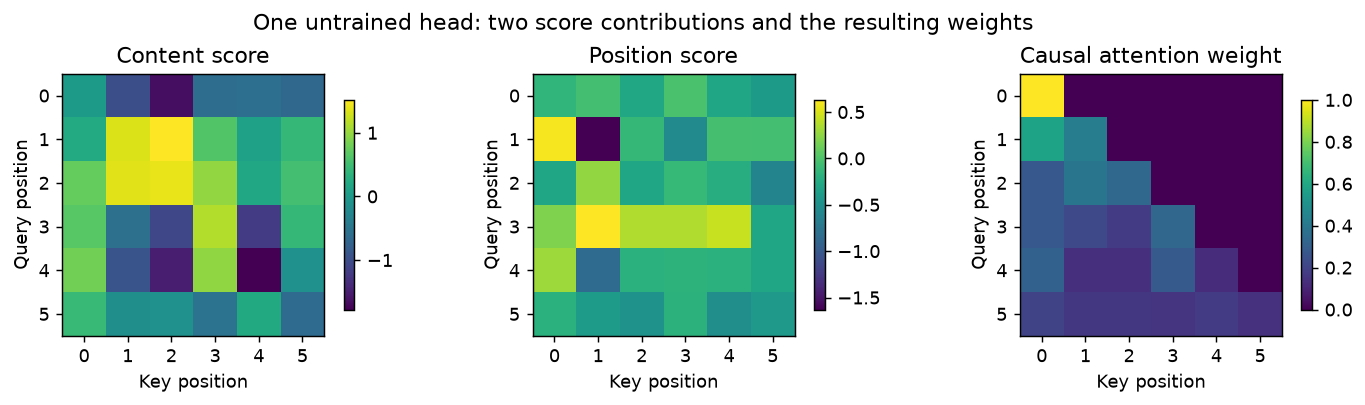

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), layout='constrained')
for ax, matrix, title in zip(axes,
        (content_scores[0, 0], position_scores[0, 0], probabilities[0, 0]),
        ('Content score', 'Position score', 'Causal attention weight')):
    image = ax.imshow(np.array(matrix), cmap='viridis')
    ax.set(title=title, xlabel='Key position', ylabel='Query position', xticks=range(T), yticks=range(T))
    fig.colorbar(image, ax=ax, shrink=.8)
fig.suptitle('One untrained head: two score contributions and the resulting weights')
plt.show()

## 5. Do the content computation directly in latent space

For one head, the expanded content keys are `C @ Wk.T`. Associativity gives
`Q @ (C @ Wk.T).T = (Q @ Wk) @ C.T`. We can move the key up-projection onto
the current queries. The cached content then needs only `C`.

The value computation has the same property:
`A @ (C @ Wv.T) = (A @ C) @ Wv.T`. Attention weights `A` first combine latent
vectors; the value up-projection acts on that mixture.

These identities preserve the model's output. The following cell checks
both identities for all heads using the same weights and activations.
For a step-by-step introduction to these index expressions, open
[notebook 14 — einsum](14_einsum_tutorial.ipynb).


In [25]:
# Move each head's key up-projection onto its current queries.
latent_queries = mx.einsum('bhtd,hdr->bhtr', content_queries, key_weights)
latent_queries.shape

(1, 4, 6, 8)

In [26]:
# Dot the projected queries with the cached latent vectors.
absorbed_content_scores = latent_queries @ latent[:, None].swapaxes(-1, -2)
np.allclose(np.array(absorbed_content_scores), np.array(content_scores), atol=2e-6)

True

In [27]:
# Mix cached latent vectors using the same attention weights.
latent_mixture = probabilities @ latent[:, None]
latent_mixture.shape

(1, 4, 6, 8)

In [28]:
# Project the latent mixtures into each head's value features.
absorbed_heads = mx.einsum('bhtr,hvr->bhtv', latent_mixture, value_weights)
np.allclose(np.array(absorbed_heads), np.array(heads), atol=2e-6)

True

In [29]:
absorbed_output = attention.output(absorbed_heads)
mx.abs(absorbed_output - manual_output).max()

array(8.9407e-08, dtype=float32)

## 6. Append tokens with the compressed cache

`decode(chunk, cache)` returns the chunk's outputs and the updated cache.
The two cache arrays contain normalized KV latents `[B, past_length, R]` and
rotated positional keys `[B, 1, past_length, Dr]`. The cached length supplies
the RoPE offset for the next chunk.

For a multi-token chunk, the causal mask lets each query see the earlier cache
and its own chunk prefix. Cache contents are activations computed with the
current model weights; begin with an empty cache after changing those weights.

In [30]:
cache = None
pieces = []
start = 0
for chunk_length in (2, 1, 3):
    output, cache = attention.decode(x[:, start:start + chunk_length], cache)
    pieces.append(output)
    start += chunk_length
    print(f'After {start} positions: latent {cache[0].shape}, positional key {cache[1].shape}')
chunked = mx.concatenate(pieces, axis=1)
np.testing.assert_allclose(np.array(chunked), np.array(manual_output), rtol=2e-5, atol=2e-6)
print('Chunked compressed-cache decoding matches the full causal forward pass.')

After 2 positions: latent (1, 2, 8), positional key (1, 1, 2, 4)
After 3 positions: latent (1, 3, 8), positional key (1, 1, 3, 4)
After 6 positions: latent (1, 6, 8), positional key (1, 1, 6, 4)
Chunked compressed-cache decoding matches the full causal forward pass.


## 7. Count cache elements

Expanded MLA keys/values need `H × (Dc + Dr + Dv)` elements per token per layer.
The compressed cache uses `R + Dr`. These counts describe retained activation
storage. Model weights and temporary attention-score arrays are additional.

The plot calculates storage for this notebook's dimensions and a two-byte
cache dtype. Our verification above uses float32. Cache compression alone
does not establish a throughput gain; the matrix shapes and implementation
also affect runtime.

In [31]:
expanded_per_token = H * (Dc + Dr + Dv)
compressed_per_token = R + Dr
{'expanded elements/token/layer': expanded_per_token,
 'compressed elements/token/layer': compressed_per_token,
 'reduction factor': expanded_per_token / compressed_per_token}


{'expanded elements/token/layer': 80, 'compressed elements/token/layer': 12, 'reduction factor': 6.666666666666667}

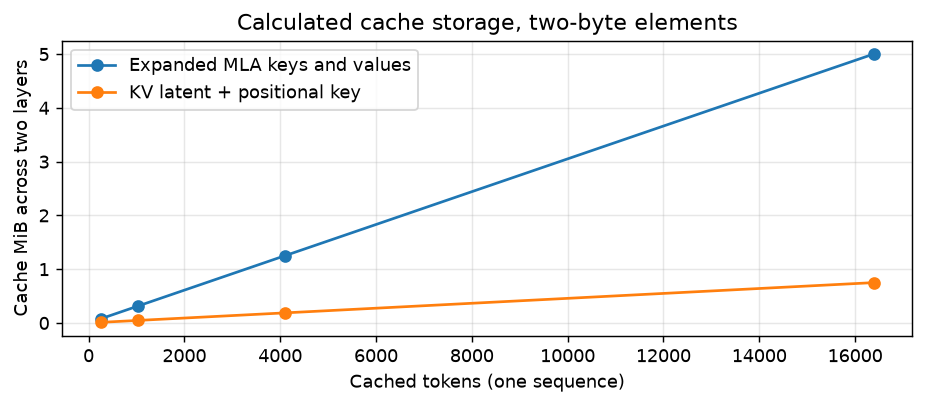

In [32]:
lengths = np.array([256, 1024, 4096, 16384])
bytes_per_element = 2
fig, ax = plt.subplots(figsize=(7, 3), layout='constrained')
for count, label in ((expanded_per_token, 'Expanded MLA keys and values'),
                      (compressed_per_token, 'KV latent + positional key')):
    mib = lengths * config.n_layers * count * bytes_per_element / 2**20
    ax.plot(lengths, mib, marker='o', label=label)
ax.set(xlabel='Cached tokens (one sequence)', ylabel='Cache MiB across two layers',
       title='Calculated cache storage, two-byte elements')
ax.legend()
ax.grid(alpha=.3)
plt.show()

## 8. Train MLA inside a tiny GPT

The GPT uses this attention module in every block and ordinary dense FFNs.
The next cells use the production compiled loss/gradient function to memorize
one repeated passage. Cross-entropy is measured on the same fixed windows
throughout this small demonstration.

In [33]:
tokenizer = Tokenizer.from_file(str(root / 'artifacts/tokenization/fineweb2-rus-bpe-8k-02/tokenizer.json'))
model_config = GPTConfig(vocab_size=tokenizer.get_vocab_size(), d_model=32, n_heads=4, n_layers=2,
                         context_length=32, position_encoding='rope', attention_architecture='mla',
                         mla_q_rank=16, mla_kv_rank=8, mla_qk_head_dim=8,
                         mla_rope_head_dim=4, mla_v_head_dim=8)
mx.random.seed(42)
model = GPT(model_config)
text = 'Утром мы вышли из дома и пошли в парк. В парке росли высокие деревья. На скамейке лежала книга. Мы открыли книгу и начали читать.'
ids = tokenizer.encode(text, add_special_tokens=False).ids
corpus = mx.array((ids + [tokenizer.token_to_id('<|endoftext|>')]) * 8)
probe_x, probe_y = get_batch(corpus, 4, 32, random.Random(123))
training = TrainConfig(steps=250, batch_size=4, learning_rate=.003, weight_decay=0,
                        lr_schedule='cosine', warmup_steps=10, min_learning_rate=.0003,
                        compile_step=True)
optimizer = make_optimizer(training, model_config)
loss_and_grad = make_loss_and_grad(model, True)
initial_ce = model(probe_x, probe_y)[1].item()
{'parameters': sum(p.size for _, p in tree_flatten(model.parameters())),
 'initial fixed-passage CE': initial_ce}

{'parameters': 279472, 'initial fixed-passage CE': 8.96702766418457}

Update  25: fixed-passage CE 5.3076
Update  50: fixed-passage CE 2.5492
Update  75: fixed-passage CE 1.3032
Update 100: fixed-passage CE 0.5757
Update 125: fixed-passage CE 0.2824
Update 150: fixed-passage CE 0.1550
Update 175: fixed-passage CE 0.1068
Update 200: fixed-passage CE 0.0848
Update 225: fixed-passage CE 0.0680
Update 250: fixed-passage CE 0.0651
CE: 8.9670 → 0.0651; saved weights reload with identical logits.


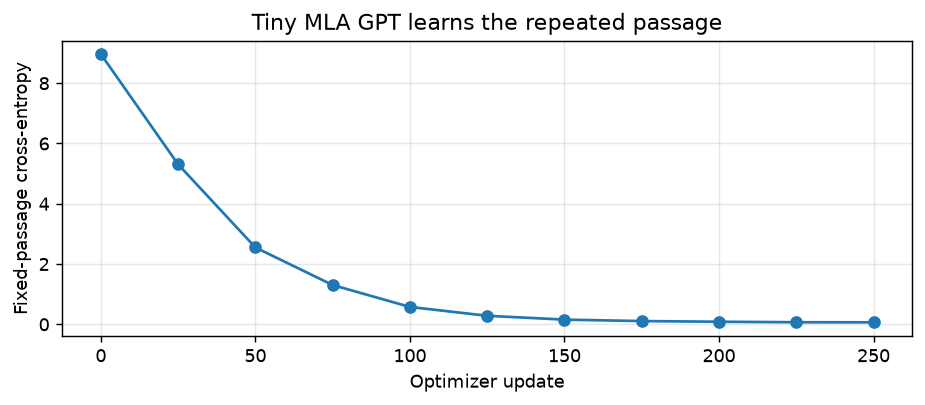

In [34]:
generator = random.Random(7)
history = [(0, initial_ce)]
for step in range(1, training.steps + 1):
    batch_x, batch_y = get_batch(corpus, training.batch_size, model_config.context_length, generator)
    loss, grads = loss_and_grad(batch_x, batch_y)
    grads, _ = optim.clip_grad_norm(grads, training.grad_clip)
    optimizer.learning_rate = learning_rate_at_step(training, step)
    optimizer.update(model, grads)
    mx.eval(loss, model.parameters(), optimizer.state)
    if step % 25 == 0:
        ce = model(probe_x, probe_y)[1].item()
        history.append((step, ce))
        print(f'Update {step:3d}: fixed-passage CE {ce:.4f}')
final_ce = model(probe_x, probe_y)[1].item()
assert final_ce < initial_ce
fig, ax = plt.subplots(figsize=(7, 3), layout='constrained')
ax.plot(*zip(*history), marker='o')
ax.set(xlabel='Optimizer update', ylabel='Fixed-passage cross-entropy',
       title='Tiny MLA GPT learns the repeated passage')
ax.grid(alpha=.3)
plt.show()
with tempfile.TemporaryDirectory() as temporary:
    path = Path(temporary) / 'mla.safetensors'
    model.save_weights(str(path))
    restored = GPT(model_config)
    restored.load_weights(str(path))
    np.testing.assert_array_equal(np.array(model(probe_x)[0]), np.array(restored(probe_x)[0]))
print(f'CE: {initial_ce:.4f} → {final_ce:.4f}; saved weights reload with identical logits.')

## Run a small corpus experiment

The prepared config is `configs/pretraining/sequential_gpt_mlx_mla_tiny.toml`.
Use the command in the model module README. It trains for 1,000 updates on the
existing token cache and writes the usual loss, statistics, samples and
resumable checkpoints under `artifacts/pretraining/gpt-mlx-mla-tiny-*`.

This notebook uses MLX, standard parameterization, full causal
attention and ordinary RoPE with base 10,000. The module also supports
sliding-window masks and fused training in the patched MLX environment. Its attention dimensions are
explicit config fields. The attention module exposes compressed-cache decoding;
GPT's current generation loop recomputes the cropped context on each step.

## Sources and implementation scope

- [DeepSeek-V2, sections 2.1 and Appendix C](https://arxiv.org/html/2405.04434v5):
  joint KV compression, query compression, decoupled RoPE and cache algebra.
- [DeepSeek-V3, section 2.1.1](https://arxiv.org/html/2412.19437v2): the MLA
  formulation retained in V3.
- [DeepSeek-V3 inference code](https://github.com/deepseek-ai/DeepSeek-V3/blob/main/inference/model.py):
  RMSNorm placement and the expanded/absorbed evaluation paths.

Our surrounding GPT retains its LayerNorms, GELU FFNs and tied embeddings.
The implementation uses float32 reference operations and dynamically concatenated
caches. DeepSeek's distributed execution, FP8 kernels and long-context YaRN
scaling are outside this example. μP transfer for these projection dimensions
has not been measured. Quality, cache size and throughput can be measured
separately in future architecture comparisons.